In [ ]:
from v2_fm_pmssm.data import *

In [2]:
from flow_matching.path.scheduler import CondOTScheduler
from flow_matching.path import AffineProbPath
from flow_matching.solver import ODESolver
from flow_matching.utils import ModelWrapper

from x_transformers import ContinuousTransformerWrapper, Encoder

/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
import sklearn.datasets as skld
import torch
import torch.nn as nn
from torch.nn import functional as F

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


In [5]:
# parameter, parameter_table, point_id, _ = load_data('/u/yinya/archive/gen_flat_v2_test/ntuples')
parameter, parameter_table, point_id, _ = load_data('/u/yinya/archive/gen_flat_v2/ntuples', max_files=20)

---Load pMSSM dataset v2---
Loading files: 20/20
Loaded 20 files from ['/u/yinya/archive/gen_flat_v2/ntuples']
Total samples: 160000


In [6]:
var_registry = select(all_var)
dataset = pMSSM_Dataset(parameter_table, point_id, var_registry, device)

In [7]:
dataset = dataset.filter_invalid(branches=['MO_Omega'])
len(dataset)

127358

In [8]:
train_idx, val_idx, test_idx = split_indices(len(dataset), (0.8, 0.1, 0.1), seed=42)
train, val, test = (dataset.subset(i) for i in (train_idx, val_idx, test_idx))
mean, std = train.transform()
val.transform(mean, std); test.transform(mean, std)

(tensor([-6.7482e+00,  3.1825e+00,  3.0015e+03, -2.8534e+01, -4.1856e+00,
         -2.4645e+00,  7.0108e+00,  2.9700e+01,  2.7889e+03,  3.5080e+03,
          3.5126e+03,  3.4951e+03, -9.0591e-01]),
 tensor([1.1168e+03, 1.1692e+03, 1.1531e+03, 4.6587e+03, 1.1528e+03, 1.1578e+03,
         1.0979e+03, 1.6615e+01, 1.2941e+03, 8.6772e+02, 8.6457e+02, 8.6635e+02,
         2.0213e+00]))

In [48]:
import sys
print(f"{sys.getsizeof(parameter_table) / 1024**2:.2f} MB")

7.93 MB


In [9]:
# hyperparameters
batch_size = 1000
learning_rate = 1e-3
max_iters = 120
eval_interval = 10
n_embd = 256
n_heads = 16
n_layers = 16
dropout = 0
# ------------

In [10]:
masks = torch.tensor([
    [True for i in range(12)] + [False],
    [False for i in range(12)] + [True],
    [False for i in range(13)],
], device=device)

In [11]:
# Transformer Backbone

class Encoder_Transformer(nn.Module):
    def __init__(self, n_embd=n_embd, n_layers=n_layers, n_heads=n_heads):
        super().__init__()
        self.known_embedding = nn.Embedding(2, n_embd) # This will be passed to x-transformer as sum_embeds

        self.transformer = ContinuousTransformerWrapper(
            dim_in = 1,
            dim_out = 1,
            max_seq_len = 14,
            attn_layers = Encoder(
                dim = n_embd,
                depth = n_layers,
                heads = n_heads
            )
)

    def forward(self, idx, known=None):
        '''
        idx: (B, 3), Input[0] = [data[0], data[1], time]
        known: (2,) or (B, 2), List or torch.tensor, dtype = torch.bool
        '''
        B, T = idx.shape

        if known is None:
            known = torch.zeros((B, 13), dtype=torch.bool, device=device)
        else:
            known = torch.as_tensor(known, dtype=torch.bool, device=device)
            if known.ndim == 1:
                known = known.expand(B, -1)

        # Append True for time dimension
        known_full = torch.cat([known, known.new_ones((B, 1))], dim=1)  # (B,T)
        kno_emb = self.known_embedding(known_full.long())  # (B,T,C)

        velocity = self.transformer(idx.unsqueeze(-1), sum_embeds=kno_emb)
        velocity = velocity.squeeze(-1)[:, :-1]  # (B,2)

        return velocity.masked_fill(known, 0.0)

In [12]:
transformer = Encoder_Transformer()
transformer = transformer.to(device)

In [13]:
# TODO: temperary, last small batch discarded. Fix it.
index = 0
def sample_data(N, dataset:pMSSM_Dataset):
    global index
    if index + N <= len(dataset):
        index = index + N
        return dataset[index - N:index]
    index = N
    return dataset[0:N]

In [54]:
val_indices = torch.randint(len(masks), (batch_size,), device=device)
val_target = sample_data(batch_size, val)
val_times = torch.rand(batch_size, 1, device=device)
val_noise = torch.randn(batch_size, 13, device=device)
val_batch = (val_indices, val_target, val_times, val_noise)

In [14]:
path = AffineProbPath(scheduler=CondOTScheduler())

In [56]:
def train_val_loop(model, validation=False):

    if validation:
        indices, target, times, noise = val_batch
    else:
        indices = torch.randint(len(masks), (batch_size,), device=device)
        target = sample_data(batch_size, train)
        times = torch.rand(batch_size, 1, device=device)
        noise = torch.randn(batch_size, 13, device=device)

    known_masks = masks[indices]
    path_sample = path.sample(x_0=noise, x_1=target, t=times.squeeze(-1))
    positions = torch.where(known_masks, target, path_sample.x_t)
    xt = torch.column_stack([positions, times])
    model_field = model(xt, known=known_masks)

    unknown = ~known_masks
    loss = ((model_field - path_sample.dx_t)**2 * unknown).sum() / unknown.sum()

    return loss

def train_transformer_FM(model):
    opt = torch.optim.Adam(model.parameters(), learning_rate)

    loss_history = []
    for i in range(max_iters):

        loss = train_val_loop(model)
        
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % eval_interval == 0 or i == max_iters - 1:
            with torch.no_grad():
                model.eval()

                loss_val = train_val_loop(model, validation=True)
                loss_history.append([loss.item(), loss_val.item()])

                if i % eval_interval == 0:
                    print(f"step {i}: train loss {loss:.4f}, val loss {loss_val:.4f}")
                
                model.train()
    return model, loss_history


vf = Encoder_Transformer()
vf = vf.to(device)

vf.train()
vf, loss_history = train_transformer_FM(vf)

step 0: train loss 2.0405, val loss 8.3802
step 1: train loss 8.4193, val loss 3.4379
step 2: train loss 3.3901, val loss 2.0701
step 3: train loss 2.1394, val loss 2.7050
step 4: train loss 2.8338, val loss 2.8416
step 5: train loss 2.8036, val loss 2.5764
step 6: train loss 2.6803, val loss 2.2764
step 7: train loss 2.1482, val loss 2.1038
step 8: train loss 2.0953, val loss 2.0653
step 9: train loss 2.0839, val loss 2.1115


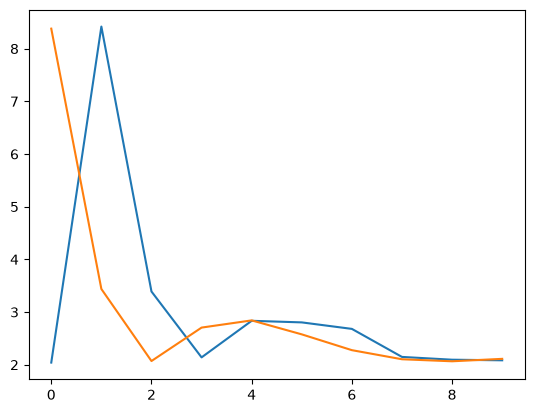

In [57]:
loss_history = torch.tensor(loss_history).cpu().detach().numpy()
plt.plot(np.arange(loss_history.shape[0])*eval_interval, loss_history[:,0])
plt.plot(np.arange(loss_history.shape[0])*eval_interval, loss_history[:,1])
plt.show()

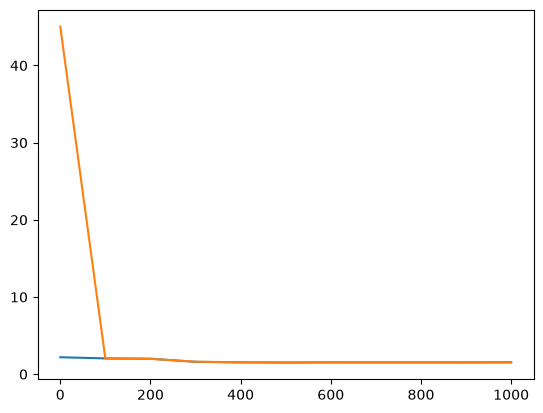

In [ ]:
# Load trained weights from a train_fm.sbatch run (needs the hyperparameter and Encoder_Transformer cells above,
# with the same n_embd / n_heads / n_layers as in train_fm.py)
run_name = "fm_31911102"   # e.g. "fm_12345678", see tests/fm_<jobid>.out

vf = Encoder_Transformer().to(device)
vf.load_state_dict(torch.load(f"training/{run_name}_weights.pt", map_location=device))
vf.eval()

loss_history = np.load(f"training/{run_name}_loss_history.npy")
plt.plot(np.arange(loss_history.shape[0])*100, loss_history[:,0])   # 500 = eval_interval in train_fm.py
plt.plot(np.arange(loss_history.shape[0])*100, loss_history[:,1])
plt.show()

## Sampling and evaluation
Generate samples with the trained velocity field `vf` for the three masks, undo the transform
(standardization, then `10**x` for `MO_Omega`), and compare with the test set.

Three scenarios, as in the training masks:
1. Joint distribution: $p(\text{inputs}, \Omega)$
2. Relic density from the inputs: $p(\Omega \mid \text{inputs})$
3. Inputs from the relic density: $p(\text{inputs} \mid \Omega)$

In [16]:
import corner

class WrappedModel(ModelWrapper):
    def forward(self, x: torch.Tensor, t: torch.Tensor, **extras):
        xt = torch.cat([x, torch.full((len(x), 1), t.item(), device=x.device)], dim=-1)
        return self.model(xt, **extras)

solver = ODESolver(velocity_model=WrappedModel(vf.eval()))  # create an ODESolver class
step_size = 0.05                     # step size for ode solver
n_samples = min(5000, len(test))     # number of test points used in the plots

names = [v.branch for v in var_registry]
i_omega = names.index('MO_Omega')

In [17]:
@torch.no_grad()
def generate(known, x_known=None, n=n_samples, chunk=5000, time_grid=None, return_intermediates=False):
    '''
    known:   (13,) bool, True = variable is fixed to its value in x_known
    x_known: (n, 13) normalized values; only the known columns are used
    returns: (n, 13) normalized samples, or (len(time_grid), n, 13) with return_intermediates
    '''
    known = torch.as_tensor(known, dtype=torch.bool, device=device)
    noise = torch.randn(n, 13, device=device)
    x_init = noise if x_known is None else torch.where(known, x_known.to(device), noise)
    T = torch.tensor([0.0, 1.0], device=device) if time_grid is None else time_grid
    out = [solver.sample(time_grid=T, x_init=x_init[s:s + chunk], method='midpoint', step_size=step_size,
                         return_intermediates=return_intermediates, known=known)
           for s in range(0, n, chunk)]
    return torch.cat(out, dim=-2)

def to_physical(x_norm, like=test):
    '''Reverse the transform with the dataset class: copy `like` (keeps mean/std), swap in x_norm, call inverse().'''
    out = like.subset(np.arange(len(x_norm)))
    out.parameters = x_norm.to(out.parameters.device).clone()
    out.inverse()
    return out.parameters.cpu().numpy()

In [18]:
# Test points used as conditions (random subset, the split indices are sorted by file)
sel = torch.randperm(len(test), generator=torch.Generator().manual_seed(0))[:n_samples].to(test.parameters.device)
test_x = test.parameters[sel]          # normalized
truth_all = to_physical(test.parameters)  # whole test set in physical units
truth = truth_all[sel.cpu().numpy()]      # the selected points in physical units

In [19]:
def _plot_values(x, j):
    '''Column j for plotting; MO_Omega is shown as log10 since it spans orders of magnitude.'''
    return (np.log10(x[:, j]), 'log10(MO_Omega)') if j == i_omega else (x[:, j], names[j])

def plot_marginals(samples, cols=None, ncols=4, bins=50):
    '''samples: {label: (n, 13) physical array}. Grid of 1D histograms as in dataset_inspection.ipynb;
    the binning range comes from the first entry (0.5-99.5 percentile).'''
    cols = list(range(len(names))) if cols is None else list(cols)
    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False, constrained_layout=True)
    for ax, j in zip(axes.flat, cols):
        ref, title = _plot_values(next(iter(samples.values())), j)
        rng = np.nanpercentile(ref[np.isfinite(ref)], [0.5, 99.5])
        for label, x in samples.items():
            v, _ = _plot_values(x, j)
            ax.hist(v[np.isfinite(v)], bins=bins, range=rng, density=True, histtype='step', label=label)
        ax.set_title(title, fontsize=9)
        ax.set_ylabel('Density')
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    plt.show()

def plot_corner(samples, cols=None):
    '''Overlaid corner plots, one color per entry of samples.'''
    cols = list(range(len(names))) if cols is None else list(cols)
    prep = {k: np.column_stack([_plot_values(x, j)[0] for j in cols]) for k, x in samples.items()}
    labels = [_plot_values(next(iter(samples.values())), j)[1] for j in cols]
    ref = next(iter(prep.values()))
    rng = [tuple(np.nanpercentile(ref[:, i], [0.5, 99.5])) for i in range(len(cols))]
    fig = None
    for c, (label, x) in enumerate(prep.items()):
        x = x[np.isfinite(x).all(axis=1)]
        fig = corner.corner(x, fig=fig, color=f'C{c}', labels=labels, range=rng, bins=30,
                            hist_kwargs={'density': True}, plot_datapoints=False, plot_density=False,
                            levels=(0.68, 0.95), label_kwargs={'fontsize': 8})
    handles = [plt.Line2D([], [], color=f'C{c}', label=label) for c, label in enumerate(prep)]
    fig.legend(handles=handles, loc='upper right', fontsize=14)
    plt.show()

### 1. Joint distribution $p(\text{inputs}, \Omega)$
Everything starts from noise (`masks[2]`).

In [20]:
gen_joint = to_physical(generate(masks[2]))
plot_marginals({'test data': truth, 'generated': gen_joint})

KeyboardInterrupt: 

In [ ]:
plot_corner({'test data': truth, 'generated': gen_joint})

Flow of 1000 points from noise to data, shown in normalized space for `IN_M_1` and `MO_Omega` (like the two-moons plots in the tutorial).

In [ ]:
T = torch.linspace(0.0, 1.0, 21, device=device)
xint = generate(masks[2], n=1000, time_grid=T, return_intermediates=True).cpu().numpy()
a, b = names.index('IN_M_1'), i_omega

f, axarr = plt.subplots(3, 7, figsize=(14, 6), sharex=True, sharey=True)
for idx, ax in enumerate(axarr.ravel()):
    ax.scatter(xint[idx][:, a], xint[idx][:, b], s=1)
    ax.set_title(f't = {T[idx].item():.2f}', fontsize=8)
    ax.set_xlim([-3, 3])
    ax.set_ylim([-3, 3])
f.supxlabel('IN_M_1 (normalized)')
f.supylabel('log10(MO_Omega) (normalized)')
plt.show()

### 2. Relic density from the inputs $p(\Omega \mid \text{inputs})$
The 12 inputs of each test point are fixed (`masks[0]`), only $\Omega$ is generated.
$\Omega$ is a deterministic function of the inputs, so a good model puts the points on the diagonal.

In [ ]:
gen_omega = to_physical(generate(masks[0], x_known=test_x))
t_om, g_om = truth[:, i_omega], gen_omega[:, i_omega]
m1 = np.abs(truth[:, names.index('IN_M_1')])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

ax = axes[0]
ax.scatter(t_om, g_om, s=1, alpha=0.5)
lims = [min(t_om.min(), g_om.min()), max(t_om.max(), g_om.max())]
ax.plot(lims, lims, 'r--', lw=1)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('true MO_Omega'); ax.set_ylabel('generated MO_Omega')

ax = axes[1]
ax.hist(np.log10(g_om / t_om), bins=60)
ax.set_xlabel('log10(generated / true)'); ax.set_ylabel('Count')

ax = axes[2]  # as in dataset_inspection.ipynb, with |M_1| in place of m_chi_10
ax.scatter(m1, t_om, s=1, label='test data')
ax.scatter(m1, g_om, s=1, alpha=0.5, label='generated')
ax.axvline(91.19/2, color='red', linestyle='--', label=r'$m_Z/2$')
ax.axvline(125.25/2, color='blue', linestyle='--', label=r'$m_h/2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(1e1, 1e4); ax.set_ylim(1e-4, 1e1)
ax.set_xlabel('|IN_M_1|'); ax.set_ylabel('MO_Omega')
ax.legend(markerscale=5, fontsize=8)
plt.show()

print(f"median |log10(generated/true)| = {np.median(np.abs(np.log10(g_om / t_om))):.3f}")

### 3. Inputs from the relic density $p(\text{inputs} \mid \Omega)$
$\Omega$ of each test point is fixed (`masks[1]`), the 12 inputs are generated.
Over many test points the marginals should match the test data.

In [ ]:
gen_inputs = to_physical(generate(masks[1], x_known=test_x))
plot_marginals({'test data': truth, 'generated': gen_inputs}, cols=range(12))

Fix one value, $\Omega = 0.12$ (Planck), and compare with test points in a narrow band around it
(like the $p(var2 \mid var1=a)$ histogram in the tutorial).

In [ ]:
omega_0 = 0.12
x_fixed = torch.zeros(n_samples, 13, device=device)
x_fixed[:, i_omega] = (np.log10(omega_0) - test.mean[i_omega].item()) / test.std[i_omega].item()  # same transform as the data
gen_fixed = to_physical(generate(masks[1], x_known=x_fixed))

band = truth_all[np.abs(np.log10(truth_all[:, i_omega]) - np.log10(omega_0)) < 0.05]
print(f"test points with |log10(Omega) - log10({omega_0})| < 0.05: {len(band)}")
plot_marginals({f'test data, |dlog10 Omega| < 0.05': band, f'generated, Omega = {omega_0}': gen_fixed}, cols=range(12))